<a href="https://colab.research.google.com/github/CodeWithYokesh/Skin-Cancer/blob/main/densenet121.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# New Section

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Load CSV from your specific Colab path
csv_path = "/content/ISIC_2019_Training_GroundTruth.csv"
df = pd.read_csv(csv_path)

# 2. Function to group the ISIC labels into 4 required target categories
def assign_4_classes(row):
    if row.get('MEL', 0) == 1.0:
        return 0  # Melanoma
    elif row.get('BCC', 0) == 1.0:
        return 1  # BCC
    elif row.get('SCC', 0) == 1.0:
        return 2  # SCC
    else:
        return 3  # Benign (NV, BKL, AK, DF, VASC)

# Apply mapping function across every row of the dataframe
df['label'] = df.apply(assign_4_classes, axis=1)

# Create human-readable names for output reports
class_names = {0: 'Melanoma', 1: 'BCC', 2: 'SCC', 3: 'Benign'}
df['class_name'] = df['label'].map(class_names)

# Print distribution summary
print("--- Class Distribution ---")
print(df['class_name'].value_counts())

# 3. Perform 80% Train / 20% Validation split
train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df['label']
)

print(f"\nTraining set size   : {len(train_df)}")
print(f"Validation set size : {len(val_df)}")

--- Class Distribution ---
class_name
Benign      16858
Melanoma     4522
BCC          3323
SCC           628
Name: count, dtype: int64

Training set size   : 20264
Validation set size : 5067


In [ ]:
import os
print([f for f in os.listdir('/content') if os.path.isdir(os.path.join('/content', f))])

['.config', 'sample_data']


In [ ]:
!pip install -q kaggle
!mkdir -p ~/.kaggle

!mkdir -p ~/.kaggle && echo KGAT_110ef97a4e6ba4f5fc0e5a58561d11c0 > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

!kaggle datasets download -d andrewmvd/isic-2019 -p /content/ --unzip

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/isic-2019
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)
100% 9.10G/9.10G [09:02<00:00, 18.0MB/s]

yokesh


Could not delete zip file, got [Errno 2] No such file or directory: '/content/isic-2019.zip'


In [ ]:
IMG_DIR = "/content/ISIC_2019_Training_Input/ISIC_2019_Training_Input"

In [18]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

# 1. Device Setup
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing on device: {DEVICE}")

# 2. Load CSV & Create 80 / 10 / 10 Split
csv_path = "/content/ISIC_2019_Training_GroundTruth.csv"
df = pd.read_csv(csv_path)

def assign_4_classes(row):
    if row.get('MEL', 0) == 1.0:
        return 0  # Melanoma
    elif row.get('BCC', 0) == 1.0:
        return 1  # BCC
    elif row.get('SCC', 0) == 1.0:
        return 2  # SCC
    else:
        return 3  # Benign

df['label'] = df.apply(assign_4_classes, axis=1)

# Step A: 80% Train, 20% Temp
train_df, temp_df = train_test_split(
    df, test_size=0.20, random_state=42, stratify=df['label']
)
# Step B: Split 20% Temp into 10% Val and 10% Test
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df['label']
)

print(f"Dataset Split -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# 3. Transforms
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    'val_test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
}

# 4. Dataset Class
class ISICDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = str(self.df.loc[idx, 'image']) + '.jpg'
        img_path = os.path.join(self.img_dir, img_name)

        if not os.path.exists(img_path):
            raise FileNotFoundError(f"Image not found at path: {img_path}")

        image = Image.open(img_path).convert('RGB')
        label = int(self.df.loc[idx, 'label'])

        if self.transform:
            image = self.transform(image)

        return image, label

IMG_DIR = "/content/ISIC_2019_Training_Input/ISIC_2019_Training_Input"

train_dataset = ISICDataset(train_df, IMG_DIR, transform=data_transforms['train'])
val_dataset   = ISICDataset(val_df, IMG_DIR, transform=data_transforms['val_test'])
test_dataset  = ISICDataset(test_df, IMG_DIR, transform=data_transforms['val_test'])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# 5. Calculate Balanced Class Weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label']),
    y=train_df['label'].values
)
weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)

# 6. Model & Loss Setup
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
in_features = model.classifier.in_features
model.classifier = nn.Linear(in_features, 4)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# 7. Training Loop (10 Epochs with Best Model Saving)
best_val_f1 = 0.0

print("\nStarting Training Pipeline (10 Epochs)...")
for epoch in range(10):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)

    train_loss = running_loss / len(train_dataset)

    # Validation check
    model.eval()
    val_preds, val_labels = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    _, _, current_f1, _ = precision_recall_fscore_support(
        val_labels, val_preds, average='weighted', zero_division=0
    )

    print(f"Epoch {epoch+1}/10 | Train Loss: {train_loss:.4f} | Val Weighted F1: {current_f1:.4f}")

    if current_f1 > best_val_f1:
        best_val_f1 = current_f1
        torch.save(model.state_dict(), 'densenet121_best_model.pth')
        print(" Saved new best checkpoint!")

# 8. FINAL EVALUATION ON HELD-OUT TEST SET
print("\n" + "="*45)
print("     EVALUATING BEST MODEL ON HELD-OUT TEST SET (10%)")
print("="*45)

model.load_state_dict(torch.load('densenet121_best_model.pth'))
model.eval()

test_preds, test_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

acc = accuracy_score(test_labels, test_preds)
precision, recall, f1, _ = precision_recall_fscore_support(
    test_labels, test_preds, average='weighted', zero_division=0
)

print(f"\nFinal Test Accuracy : {acc * 100:.2f}%")
print(f"Final Test Precision: {precision:.4f}")
print(f"Final Test Recall   : {recall:.4f}")
print(f"Final Test F1-Score : {f1:.4f}\n")
print(classification_report(test_labels, test_preds, target_names=['Melanoma', 'BCC', 'SCC', 'Benign']))

Executing on device: cuda
Dataset Split -> Train: 20264 | Val: 2533 | Test: 2534

Starting Training Pipeline (10 Epochs)...
Epoch 1/10 | Train Loss: 0.8352 | Val Weighted F1: 0.7256
 Saved new best checkpoint!
Epoch 2/10 | Train Loss: 0.6315 | Val Weighted F1: 0.7398
 Saved new best checkpoint!
Epoch 3/10 | Train Loss: 0.5616 | Val Weighted F1: 0.7820
 Saved new best checkpoint!
Epoch 4/10 | Train Loss: 0.4762 | Val Weighted F1: 0.7385
Epoch 5/10 | Train Loss: 0.4311 | Val Weighted F1: 0.7918
 Saved new best checkpoint!
Epoch 6/10 | Train Loss: 0.3671 | Val Weighted F1: 0.7672
Epoch 7/10 | Train Loss: 0.3457 | Val Weighted F1: 0.7736
Epoch 8/10 | Train Loss: 0.3268 | Val Weighted F1: 0.7944
 Saved new best checkpoint!
Epoch 9/10 | Train Loss: 0.2838 | Val Weighted F1: 0.8048
 Saved new best checkpoint!
Epoch 10/10 | Train Loss: 0.2580 | Val Weighted F1: 0.7985

     EVALUATING BEST MODEL ON HELD-OUT TEST SET (10%)

Final Test Accuracy : 80.47%
Final Test Precision: 0.8447
Final Test Re

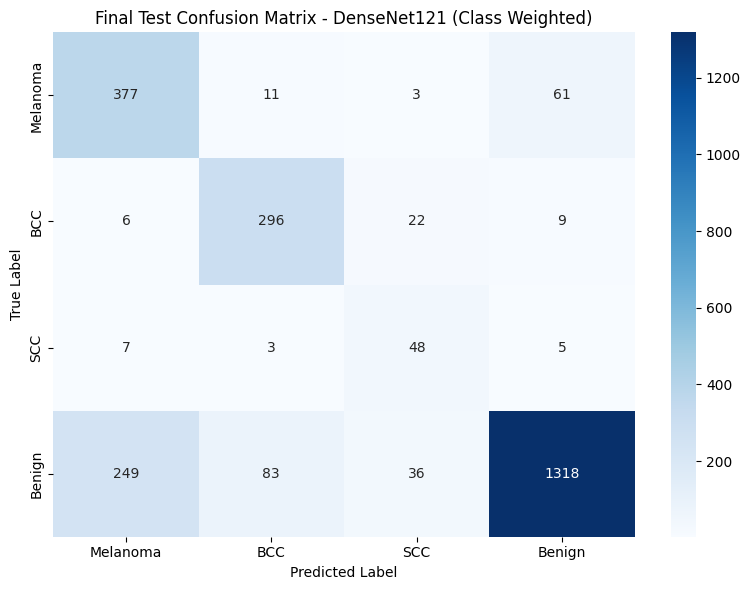

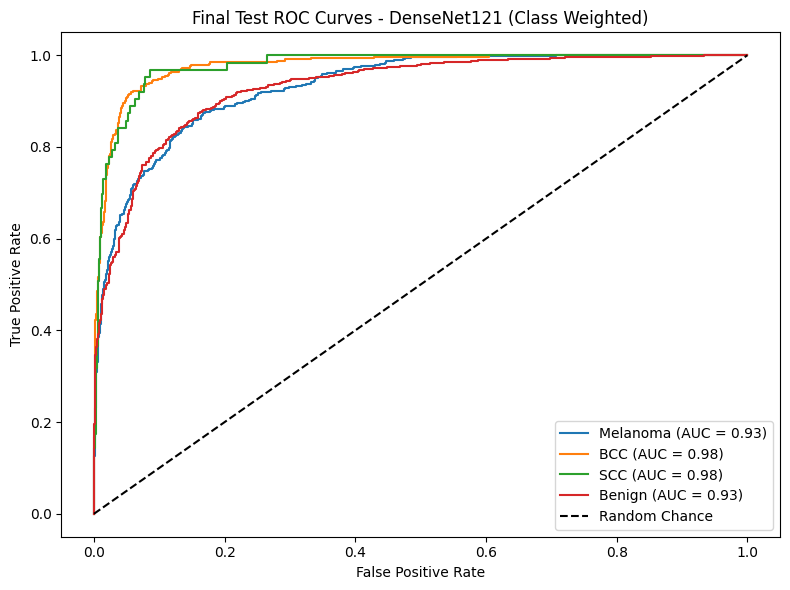

In [19]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

# 1. Load best model weights and evaluate test loader
model.load_state_dict(torch.load('densenet121_best_model.pth'))
model.eval()

test_preds, test_labels, test_probs = [], [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)

        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())
        test_probs.extend(probs.cpu().numpy())

test_preds = np.array(test_preds)
test_labels = np.array(test_labels)
test_probs = np.array(test_probs)
class_names = ['Melanoma', 'BCC', 'SCC', 'Benign']

# 2. Confusion Matrix
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Final Test Confusion Matrix - DenseNet121 (Class Weighted)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('final_test_confusion_matrix.png', dpi=300)
plt.show()

# 3. ROC Curves
y_onehot = label_binarize(test_labels, classes=[0, 1, 2, 3])
plt.figure(figsize=(8, 6))

for i in range(4):
    fpr, tpr, _ = roc_curve(y_onehot[:, i], test_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{class_names[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Final Test ROC Curves - DenseNet121 (Class Weighted)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('final_test_roc_curves.png', dpi=300)
plt.show()